# Projeto de Inteligência Artificial (2026-2027)
## Otimização de Cadeias de Abastecimento de Comida Local
### Notebook Principal — Grupo 03

| Nome | Número |
|---|---|
| João Soares | 26593 |
| Edgar Casal | 31026 |
| João Machado | 31510 |
| Rafael Soares | 24869 |

**Índice:** 1. Introdução · 2. Análise exploratória · 3. Modelação · 4. Pesquisa informada ·
5. Pesquisa local · 6. CSP · 7. Análise de resultados · 8. Conclusão

### Resumo da solução
O agente decide **que veículo recolhe cada produtor em cada dia** e **por que ordem faz as paragens**,
gastando o mínimo de km e respeitando as janelas temporais, a capacidade e a passagem pelo armazém (máx. 24 h).

```
Dados ──► Lotes (produtor, dia) ──► CSP: que veículo faz cada lote ──► Greedy / A*: ordem das paragens ──► Hill Climbing: melhorar
                                              └──────────── todos usam o mesmo verificador de rotas (model.py) ────────────┘
```

| Passo | Ficheiro | Ideia |
|---|---|---|
| Modelo | `model.py` | Juntar os itens em **lotes** (produtor, dia). Um **simulador** calcula os horários de uma rota e diz se é viável. |
| Pesquisa informada | `informed.py` | **Ordem das paragens** de cada veículo: Greedy e A*, com 2 heurísticas. |
| Pesquisa local | `local_search.py` | **Melhorar** a rota da Greedy: Hill Climbing. |
| CSP | `csp.py` | **Que veículo** faz cada lote: backtracking + forward checking + AC-3. Corre primeiro, mas é explicado no fim (ordem dos slides). |

**Resultado:** 580,90 km (tiny) e 1129,32 km (small), as melhores soluções possíveis dentro do nosso modelo.

---
## 1. Introdução

Na União Europeia cresce a procura por **produtos locais e circuitos curtos**, que reduzem emissões e
desperdício. Mas os pequenos produtores estão espalhados pelo território, vendem pequenas quantidades e os
produtos são perecíveis: o transporte é caro e tem horários apertados.

Uma plataforma liga três atores:
* **Produtores** — disponibilizam produtos numa **janela de disponibilidade**;
* **Clientes** — fazem encomendas, escolhem o **local** e a **janela de entrega**;
* **Armazém (centro de recolha)** — onde os produtos são agregados e onde estão os veículos.

Todo o produto segue o fluxo **produtor → armazém → local de entrega**. O objetivo é planear as rotas dos
veículos **minimizando os km** e cumprindo todas as regras.

In [120]:
import os
import sys
import math
import itertools

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from IPython.display import display, Markdown

# Pasta do projeto (funciona a partir de Notebooks/ ou da raiz) e módulos em src/
ROOT = os.path.abspath(".." if os.path.exists("../src") else ".")
sys.path.insert(0, os.path.join(ROOT, "src"))

from model import Problem, Plan, check_route, check_solution, solution_cost, route_table, plan_result
from informed import route_search, solve, greedy_assignment, HEURISTICS
from csp import RoutingCSP
from local_search import hill_climbing

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 160)

# Estilo dos gráficos (paleta categórica validada + tinta neutra)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (10, 5), "font.size": 10, "axes.edgecolor": INK2,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "legend.frameon": False,
})

# Carregar as duas instâncias
tiny = Problem(os.path.join(ROOT, "data_tiny"))
small = Problem(os.path.join(ROOT, "data_small"))
DATASETS = [tiny, small]
pd.concat([pb.summary() for pb in DATASETS])

,produtores,locais de entrega,veículos,encomendas,pedidos (itens),lotes de recolha,peso total (kg),capacidade total (kg)
data_tiny,3,5,2,12,40,6,270.0,350.0
data_small,6,7,2,25,80,12,580.0,550.0


---
## 2. Análise exploratória (resumo)

A análise completa está em **`02_eda_tiny.ipynb`**. O que aprendemos e o que isso mudou no modelo:

| Observação | Consequência |
|---|---|
| Dados íntegros (sem nulos, chaves válidas); matriz de distâncias completa e simétrica | Usamos os CSVs diretamente; custo = km da matriz |
| As janelas dos itens de um produtor num dia cruzam-se **sempre** | Agrupamos os itens em **lotes (produtor, dia)**, recolhidos numa só visita |
| Os itens de uma encomenda têm a mesma janela de entrega | Uma entrega por encomenda |
| Algumas encomendas só são entregues no dia seguinte | A regra das **24 h no armazém** tem de ser verificada |
| Produtores muito afastados (ex.: Esposende ↔ Vieira do Minho ≈ 100 min) | Os 2 veículos têm de **dividir os produtores** entre si |

Os lotes de cada instância:

In [121]:
def lots_table(pb):
    rows = []
    for g, reqs in pb.groups.items():
        r = [pb.requests[x] for x in reqs]
        rows.append({"lote (produtor, dia)": pb.group_label(g), "itens": len(r), "kg": round(pb.weight(reqs), 1),
                     "janela de recolha": f"{pb.clock(max(x.pickup_start for x in r))} - "
                                          f"{pb.clock(min(x.pickup_end for x in r))[6:]}"})
    return pd.DataFrame(rows)

display(Markdown("**tiny** (6 lotes)"), lots_table(tiny), Markdown("**small** (12 lotes)"), lots_table(small))

**tiny** (6 lotes)

,"lote (produtor, dia)",itens,kg,janela de recolha
0,Hortas Valente (30/10),8,52.0,30/10 09:30 - 09:45
1,Campos Leite (30/10),9,77.6,30/10 09:00 - 10:30
2,Horta Morais (30/10),7,37.3,30/10 08:00 - 09:45
3,Hortas Valente (31/10),5,41.1,31/10 09:00 - 11:15
4,Campos Leite (31/10),5,29.9,31/10 08:15 - 10:00
5,Horta Morais (31/10),6,32.1,31/10 07:45 - 09:45


**small** (12 lotes)

,"lote (produtor, dia)",itens,kg,janela de recolha
0,Hortas Valente (30/10),7,43.7,30/10 08:45 - 10:15
1,Campos Leite (30/10),6,31.5,30/10 09:30 - 11:00
2,Horta Morais (30/10),6,50.7,30/10 08:15 - 10:15
3,Courela Carvalho (30/10),6,48.0,30/10 07:15 - 09:00
4,Horta Antunes (30/10),8,44.3,30/10 09:45 - 11:15
5,Campos Oliveira (30/10),13,120.5,30/10 08:15 - 09:45
6,Hortas Valente (31/10),4,14.2,31/10 08:00 - 09:45
7,Campos Leite (31/10),8,64.1,31/10 09:00 - 10:30
8,Horta Morais (31/10),9,71.1,31/10 09:45 - 11:15
9,Courela Carvalho (31/10),4,32.9,31/10 07:15 - 09:00


---
## 3. Modelação (`model.py`)

### 3.1 Regras (ficheiro `rules.csv`)
1. O veículo **recolhe** o produto no produtor, dentro da janela de disponibilidade (10 min de serviço).
2. Leva-o ao **armazém**, onde é **descarregado** (15 min).
3. Mais tarde é **carregado** (15 min) e **entregue** dentro da janela de entrega (10 min de serviço).
4. Entre a chegada ao armazém e a carga passam **no máximo 24 h**.

As janelas limitam o **início** do serviço: se o veículo chega cedo, espera.

### 3.2 Decisões de modelação
| Decisão | Porquê |
|---|---|
| **Lote** = todos os itens de um produtor num dia, recolhidos por **um** veículo numa visita | As janelas cruzam-se sempre (EDA). Em vez de decidir 40/80 itens, decidimos 6/12 lotes |
| Cada item vai **sempre no mesmo veículo** (recolha → armazém → entrega) | Assim cada rota pode ser verificada sozinha |
| O veículo vai ao armazém **só quando precisa**: antes de entregar o que ainda não carregou, no fim do dia e no fim da rota | Ninguém tem de decidir as passagens pelo armazém |
| Os horários são "o mais cedo possível"; a carga é feita "à justa" para a primeira entrega | Uma regra simples e sempre igual para calcular horários |
| **Custo = total de km** | É o objetivo pedido |

Consequência da 2.ª decisão: se os itens de uma encomenda vierem de lotes de veículos diferentes, a encomenda
chega em duas entregas. (Começámos por pôr cada encomenda inteira num só veículo, mas no small isso é
impossível com 2 veículos.)

### 3.3 Classes
| Classe | O que é |
|---|---|
| `Request` | um item a transportar: peso, produtor e janela de recolha, local e janela de entrega |
| `Vehicle` | um veículo: capacidade e armazém |
| `Task` | uma paragem: recolha de um lote (`P`) ou entrega de uma encomenda (`D`), com a sua janela |
| `State` | onde está o veículo, que horas são, o que leva, o que está no armazém e os km feitos |
| `Plan` | o plano de um veículo: os seus lotes e a ordem das paragens |
| `Problem` | a instância lida dos CSVs |

Por exemplo, se o veículo 2 ficar com os 3 lotes de 30/10 do tiny, estas são as paragens que tem de fazer:

In [122]:
groups_30 = [g for g in tiny.groups if g[1] == 0]          # lotes do 1.º dia
reqs_30 = tiny.requests_of(groups_30)
tasks_30 = tiny.tasks_for(reqs_30)
pd.DataFrame([{"paragem": tiny.label(k), "tipo": t.kind, "janela": f"{tiny.clock(t.start)} - {tiny.clock(t.end)[6:]}",
               "kg": round(t.weight, 1)} for k, t in tasks_30.items()])

,paragem,tipo,janela,kg
0,Recolha Hortas Valente (30/10),P,30/10 09:30 - 09:45,52.0
1,Recolha Campos Leite (30/10),P,30/10 09:00 - 10:30,77.6
2,Recolha Horta Morais (30/10),P,30/10 08:00 - 09:45,37.3
3,Entrega enc.2 @ Casa 4,D,31/10 07:15 - 10:15,6.8
4,Entrega enc.4 @ Casa 3,D,30/10 11:30 - 13:45,26.3
5,Entrega enc.8 @ Casa 2,D,31/10 09:30 - 12:00,18.8
6,Entrega enc.9 @ Loja 5,D,31/10 08:15 - 09:45,36.7
7,Entrega enc.10 @ Casa 4,D,30/10 11:45 - 14:00,9.2
8,Entrega enc.11 @ Loja 1,D,30/10 10:15 - 14:00,18.0
9,Entrega enc.12 @ Casa 2,D,30/10 12:15 - 14:45,51.1


### 3.4 Verificador de viabilidade
A função `step` aplica **uma paragem** ao estado do veículo e devolve o novo estado, ou o motivo pelo qual a
paragem é impossível:
* **Recolha:** viaja até ao produtor, espera se for cedo, falha se a janela já fechou ou se excede a capacidade.
* **Entrega:** se os itens ainda não estão no veículo, vai ao armazém, descarrega e carrega. Verifica as 24 h,
  a capacidade e a janela de entrega. Entregas seguidas no mesmo dia aproveitam a mesma carga.

`check_route` aplica `step` a todas as paragens de uma rota.

**Exemplo:** veículo 2, primeiro todas as recolhas e depois todas as entregas, por ordem de janela:

In [123]:
naive = sorted(tasks_30, key=lambda k: (k[0] != "P", tasks_30[k].start))
plan_demo = Plan(groups_30, naive)
print(f"Viável: {plan_result(tiny, 2, plan_demo).feasible} | {plan_result(tiny, 2, plan_demo).distance:.2f} km")
route_table(tiny, 2, plan_demo)

Viável: True | 371.61 km


,paragem,hora,carga (kg)
0,Recolha Horta Morais (30/10),30/10 08:00,37.3
1,Recolha Campos Leite (30/10),30/10 09:00,114.9
2,Recolha Hortas Valente (30/10),30/10 09:41,166.9
3,Armazém (chegada),30/10 10:32,166.9
4,Armazém: descarga,30/10 10:32,0.0
5,Armazém: carga,30/10 10:47,104.6
6,Entrega enc.11 @ Loja 1,30/10 11:27,86.6
7,Entrega enc.4 @ Casa 3,30/10 11:46,60.3
8,Entrega enc.10 @ Casa 4,30/10 12:30,51.1
9,Entrega enc.12 @ Casa 2,30/10 13:28,0.0


O armazém aparece sozinho na rota (descarga, carga e pernoita), e as encomendas 2, 9 e 8 são entregues no dia
seguinte. Se a rota violar uma regra, o verificador diz qual:

In [124]:
tests = [("veículo 2, entregar a enc. 8 antes de recolher", 2, [naive[-1]] + naive[:-1]),
         ("veículo 2, trocar as 2 primeiras recolhas", 2, [naive[1], naive[0]] + naive[2:]),
         ("veículo 1 (150 kg), a mesma rota", 1, naive)]
for name, vid, route in tests:
    r = check_route(tiny, tiny.vehicle[vid], reqs_30, route)
    print(f"{name}: viável={r.feasible} -> {r.reason}")

veículo 2, entregar a enc. 8 antes de recolher: viável=False -> Entrega enc.8 @ Casa 2: itens ainda não recolhidos
veículo 2, trocar as 2 primeiras recolhas: viável=False -> Recolha Hortas Valente (30/10): chegaria às 30/10 10:47, janela fecha às 30/10 09:45
veículo 1 (150 kg), a mesma rota: viável=False -> capacidade excedida (166.9 > 150 kg)


### 3.5 Função de custo
`solution_cost` = **soma dos km de todos os veículos**; é **infinito** se alguma rota for inviável.

---
## 4. Pesquisa informada: Greedy e A* (`informed.py`)

### 4.1 Passo 1: que veículo faz cada lote
Antes de procurar rotas é preciso decidir que lotes faz cada veículo. Esta escolha é muito restrita (só 2 das 64
combinações do tiny são viáveis), por isso é feita por um **CSP**, explicado em detalhe na **secção 6**.
Aqui usamos apenas o resultado:

In [125]:
assignment, csp_time = {}, {}
for pb in DATASETS:
    a, st = RoutingCSP(pb).solve()          # backtracking + forward checking + AC-3 + heurísticas
    assignment[pb.name], csp_time[pb.name] = a, st["tempo (s)"]
    display(Markdown(f"**{pb.name}**"),
            pd.DataFrame([{"veículo": v, "lotes": ", ".join(pb.group_label(g) for g in gs),
                           "kg": round(pb.weight(pb.requests_of(gs)), 1)} for v, gs in a.items()]))

**data_tiny**

,veículo,lotes,kg
0,1,"Hortas Valente (31/10), Campos Leite (31/10), Horta Morais (31/10)",103.1
1,2,"Hortas Valente (30/10), Campos Leite (30/10), Horta Morais (30/10)",166.9


**data_small**

,veículo,lotes,kg
0,1,"Campos Leite (30/10), Horta Morais (30/10), Courela Carvalho (30/10), Campos Leite (31/10), Horta Morais (31/10), Courela Carvalho (31/10)",298.3
1,2,"Hortas Valente (30/10), Horta Antunes (30/10), Campos Oliveira (30/10), Hortas Valente (31/10), Horta Antunes (31/10), Campos Oliveira (31/10)",281.7


No tiny, um veículo faz o dia 30/10 e o outro o dia 31/10. No small dividem o território: o veículo 1 fica
com Braga, Terras de Bouro e Vieira do Minho; o veículo 2 com Fafe, Esposende e Guimarães.

Com os lotes atribuídos, falta a **ordem das paragens** de cada veículo.

### 4.2 Passo 2: formulação da pesquisa
| | |
|---|---|
| **Estado** | `State` (posição, hora, carga, paragens feitas, ...) |
| **Inicial** | veículo no armazém, nada feito |
| **Ações** | fazer uma das paragens que faltam |
| **Transição** | `step` do modelo (só gera estados viáveis) |
| **Objetivo** | todas as paragens feitas e regresso ao armazém |
| **Custo g(n)** | km percorridos |

Duas podas simples:
* **Janelas:** se alguma paragem que falta já não pode ser alcançada a tempo, o estado é descartado.
* **Estados repetidos:** se dois caminhos chegam ao mesmo estado, só se guarda o mais barato.

### 4.3 Heurísticas (ambas admissíveis: nunca sobrestimam os km que faltam)
* **h1 — paragem mais distante:** `max_s [ d(atual, s) + d(s, armazém) ]`, porque o veículo tem de ir a cada
  paragem e depois voltar.
* **h2 — árvore geradora mínima (MST)** da posição atual, paragens que faltam e armazém: o resto da rota é um
  caminho que liga esses pontos, e nenhum caminho é mais curto do que a MST.

**Greedy** expande o nó com menor `h(n)`: rápida, mas sem garantias. **A\*** expande o nó com menor
`f(n) = g(n) + h(n)`: com `h` admissível encontra a rota **ótima**.

### 4.4 Rotas dos 2 veículos do tiny

In [126]:
informed_rows, informed_sol = [], {}
for pb in DATASETS:
    for alg in ["greedy", "astar"]:
        for h in HEURISTICS:
            sol, stats = solve(pb, assignment[pb.name], algorithm=alg, heuristic=h)
            informed_rows += stats
            informed_sol[pb.name, alg, h] = sol
df_inf = pd.DataFrame(informed_rows)
df_inf["algoritmo"] = df_inf["algoritmo"].map({"greedy": "Greedy", "astar": "A*"})
df_inf[df_inf.dataset == "data_tiny"].drop(columns=["dataset", "encontrou"])

,algoritmo,heurística,veículo,paragens,km,nós expandidos,nós gerados,tempo (s)
0,Greedy,h1_farthest,1,8,247.63,9,16,0.0003
1,Greedy,h1_farthest,2,10,415.61,13,18,0.0005
2,Greedy,h2_mst,1,8,263.03,9,16,0.0003
3,Greedy,h2_mst,2,10,397.58,13,16,0.0005
4,A*,h1_farthest,1,8,227.32,34,51,0.0008
5,A*,h1_farthest,2,10,353.58,51,53,0.0015
6,A*,h2_mst,1,8,227.32,111,123,0.0028
7,A*,h2_mst,2,10,353.58,51,53,0.0017


**Nós expandidos** = estados retirados da fila e desenvolvidos. Rotas ótimas (A*) do tiny:

In [127]:
best_tiny = informed_sol["data_tiny", "astar", "h2_mst"]
for vid, plan in best_tiny.items():
    display(Markdown(f"**Veículo {vid}** ({tiny.vehicle[vid].capacity:.0f} kg) — "
                     f"{plan_result(tiny, vid, plan).distance:.2f} km"), route_table(tiny, vid, plan))

**Veículo 1** (150 kg) — 227.32 km

,paragem,hora,carga (kg)
0,Recolha Horta Morais (31/10),31/10 07:45,32.1
1,Recolha Campos Leite (31/10),31/10 08:30,62.0
2,Recolha Hortas Valente (31/10),31/10 09:11,103.1
3,Armazém (chegada),31/10 10:02,103.1
4,Armazém: descarga,31/10 10:02,0.0
5,Armazém: carga,31/10 10:17,103.1
6,Entrega enc.5 @ Loja 1,31/10 10:57,93.8
7,Entrega enc.1 @ Casa 3,31/10 11:16,71.8
8,Entrega enc.6 @ Casa 3,31/10 11:26,55.1
9,Entrega enc.7 @ Loja 5,31/10 11:36,21.6


**Veículo 2** (200 kg) — 353.58 km

,paragem,hora,carga (kg)
0,Recolha Horta Morais (30/10),30/10 08:00,37.3
1,Recolha Campos Leite (30/10),30/10 09:00,114.9
2,Recolha Hortas Valente (30/10),30/10 09:41,166.9
3,Armazém (chegada),30/10 10:32,166.9
4,Armazém: descarga,30/10 10:32,0.0
5,Armazém: carga,30/10 10:47,104.6
6,Entrega enc.11 @ Loja 1,30/10 11:27,86.6
7,Entrega enc.4 @ Casa 3,30/10 11:46,60.3
8,Entrega enc.10 @ Casa 4,30/10 12:30,51.1
9,Entrega enc.12 @ Casa 2,30/10 13:28,0.0


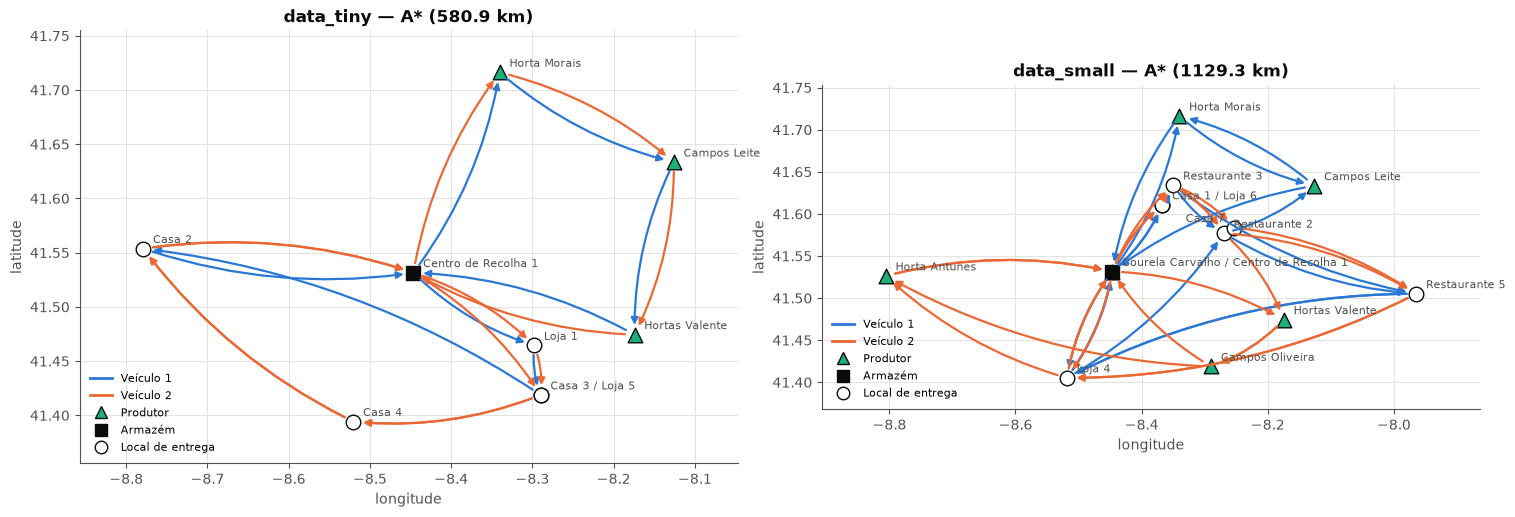

In [128]:
# Funções auxiliares para desenhar as rotas no mapa (apenas visualização)
def place_labels(ax, points):
    # escreve cada nome na primeira posição livre à volta do ponto
    renderer, placed = ax.figure.canvas.get_renderer(), []
    spots = [(7, 4, "left"), (7, -12, "left"), (-7, 4, "right"), (-7, -12, "right"), (7, 15, "left"), (-7, 15, "right")]
    for x, y, text in points:
        for dx, dy, ha in spots:
            a = ax.annotate(text, (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=8, color=INK2)
            box = a.get_window_extent(renderer).expanded(1.05, 1.15)
            if not any(box.overlaps(b) for b in placed):
                placed.append(box)
                break
            a.remove()

def plot_routes(pb, sol, title, ax):
    styles = {"producer": ("^", AQUA, "Produtor"), "collection_center": ("s", INK, "Armazém"),
              "delivery_location": ("o", "white", "Local de entrega")}
    for typ, (marker, color, _) in styles.items():
        pts = [pb.coords[l] for l, t in pb.loc_type.items() if t == typ]
        ax.scatter([p[1] for p in pts], [p[0] for p in pts], marker=marker, s=110, c=color, edgecolors=INK, zorder=3)
    colors = {1: BLUE, 2: ORANGE}
    for vid, plan in sol.items():
        tasks, depot = pb.tasks_for(pb.requests_of(plan.groups)), pb.vehicle[vid].depot
        seq = [depot] + [depot if k == "W" else tasks[k].loc for k, *_ in plan_result(pb, vid, plan).log]
        seq = [l for i, l in enumerate(seq) if i == 0 or l != seq[i - 1]]
        for a, b in zip(seq, seq[1:]):
            (y1, x1), (y2, x2) = pb.coords[a], pb.coords[b]
            ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle="-|>", color=colors[vid], lw=1.6,
                        shrinkA=7, shrinkB=7, connectionstyle=f"arc3,rad={0.12 if vid == 1 else -0.12}"))
    handles = [Line2D([], [], color=colors[v], lw=2, label=f"Veículo {v}") for v in sol]
    handles += [Line2D([], [], marker=m, ls="", markerfacecolor=c, markeredgecolor=INK, markersize=9, label=l)
                for m, c, l in styles.values()]
    ax.legend(handles=handles, loc="lower left", fontsize=8)
    ax.set_aspect(1 / math.cos(math.radians(41.5)))
    ax.margins(0.12)
    ax.set(title=title, xlabel="longitude", ylabel="latitude")

def stop_points(pb):
    names = {}
    for l, (lat, lon) in pb.coords.items():
        names.setdefault((lon, lat), []).append(pb.loc_name[l])
    return [(x, y, " / ".join(n)) for (x, y), n in names.items()]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, pb in zip(axes, DATASETS):
    sol = informed_sol[pb.name, "astar", "h2_mst"]
    plot_routes(pb, sol, f"{pb.name} — A* ({solution_cost(pb, sol):.1f} km)", ax)
plt.tight_layout()
for ax, pb in zip(axes, DATASETS):
    place_labels(ax, stop_points(pb))
plt.show()

### 4.5 Comparação (soma dos 2 veículos)

In [129]:
df_inf_total = (df_inf.groupby(["dataset", "algoritmo", "heurística"], sort=False)
                .agg({"km": "sum", "nós expandidos": "sum", "tempo (s)": "sum"})
                .round({"km": 2, "tempo (s)": 4}).reset_index())
df_inf_total

,dataset,algoritmo,heurística,km,nós expandidos,tempo (s)
0,data_tiny,Greedy,h1_farthest,663.24,22,0.0008
1,data_tiny,Greedy,h2_mst,660.61,22,0.0008
2,data_tiny,A*,h1_farthest,580.90,85,0.0023
3,data_tiny,A*,h2_mst,580.90,162,0.0045
4,data_small,Greedy,h1_farthest,1160.45,540,0.0400
5,data_small,Greedy,h2_mst,1159.31,296,0.0178
6,data_small,A*,h1_farthest,1129.32,3888,0.1756
7,data_small,A*,h2_mst,1129.32,3977,0.2132


* O **A\*** encontra as rotas ótimas com as duas heurísticas (580,90 km e 1129,32 km).
* A **Greedy** expande muito menos nós, mas as rotas são piores: +14 % no tiny e +3 % no small.
* No small o A* já precisa de milhares de nós: cresce muito com o número de paragens.

---
## 5. Pesquisa local: Hill Climbing (`local_search.py`)

Parte da solução da **Greedy (h2)** e muda a ordem das paragens de cada veículo enquanto isso baixar os km.

* **Vizinhos de uma rota:** trocar duas paragens, ou mover 1, 2 ou 3 paragens seguidas para outra posição.
* **Steepest:** testa todos os vizinhos e escolhe o melhor.
* **First improvement:** testa os vizinhos por ordem aleatória e aceita o primeiro que melhora.
* Pára quando nenhum vizinho melhora (**máximo local**). Vizinhos inviáveis nunca são aceites.

In [ ]:
hc, hc_rows = {}, []
for pb in DATASETS:
    start = informed_sol[pb.name, "greedy", "h2_mst"]
    for strategy in ["steepest", "first"]:
        best, history, moves, secs = hill_climbing(pb, start, strategy=strategy, seed=1)
        hc[pb.name, strategy] = (best, history, moves, secs)
        hc_rows.append({"dataset": pb.name, "variante": strategy, "km inicial": round(history[0], 2),
                        "km final": round(history[-1], 2), "iterações": len(history) - 1,
                        "tempo (s)": round(secs, 2), "viável": check_solution(pb, best)["viável"]})
pd.DataFrame(hc_rows)

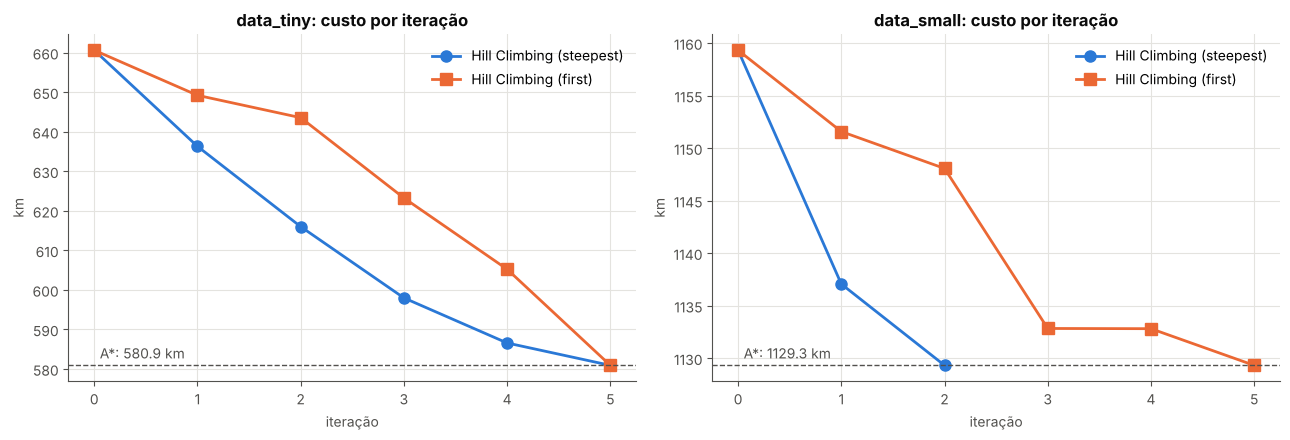

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, pb in zip(axes, DATASETS):
    optimum = solution_cost(pb, informed_sol[pb.name, "astar", "h2_mst"])
    for strategy, color, marker in [("steepest", BLUE, "o"), ("first", ORANGE, "s")]:
        history = hc[pb.name, strategy][1]
        ax.plot(range(len(history)), history, color=color, lw=2, marker=marker, ms=8, label=f"Hill Climbing ({strategy})")
    ax.axhline(optimum, color=INK2, ls="--", lw=1)
    ax.annotate(f"A*: {optimum:.1f} km", (0, optimum), xytext=(4, 5), textcoords="offset points", color=INK2)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set(title=f"{pb.name}: custo por iteração", xlabel="iteração", ylabel="km")
    ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

* Nos dois datasets o Hill Climbing chega ao **mesmo custo que o A\*** em poucas iterações.
* A **steepest** dá passos maiores (menos iterações); a **first improvement** faz iterações mais baratas.
* Mover **blocos** de paragens foi importante: só com trocas simples ficava preso num máximo local no small.

---
## 6. CSP: que veículo faz cada lote (`csp.py`)

Esta secção explica como foi obtida a atribuição dos lotes aos veículos usada na secção 4.

### 6.1 Porque é preciso um CSP
Primeiro tentámos uma regra **gulosa**: dar cada lote ao veículo onde fica mais barato, sem nunca voltar atrás.

In [ ]:
for pb in DATASETS:
    assign, failed = greedy_assignment(pb)
    print(f"{pb.name}: atribuiu {sum(map(len, assign.values()))} de {len(pb.groups)} lotes "
          f"e falhou no lote {pb.group_label(failed)}")

data_tiny: atribuiu 4 de 6 lotes e falhou no lote Campos Leite (31/10)


data_small: atribuiu 7 de 12 lotes e falhou no lote Campos Leite (31/10)


Falha nos dois datasets. Testando **todas** as 2⁶ = 64 atribuições possíveis do tiny percebe-se porquê:

In [ ]:
def feasible_assignments(pb):
    # testa todas as combinações lote -> veículo (só serve para instâncias pequenas)
    vids, G, cache = [v.vehicle_id for v in pb.vehicles], list(pb.groups), {}
    def ok(vid, gs):
        if (vid, gs) not in cache:
            cache[vid, gs] = not gs or route_search(pb, pb.vehicle[vid], pb.requests_of(gs), "greedy").route is not None
        return cache[vid, gs]
    return [c for c in itertools.product(vids, repeat=len(G))
            if all(ok(v, tuple(g for g, x in zip(G, c) if x == v)) for v in vids)]

good = feasible_assignments(tiny)
print(f"tiny: só {len(good)} de {2 ** len(tiny.groups)} atribuições são viáveis")

tiny: só 2 de 64 atribuições são viáveis


Só **2 em 64** (no small, um teste semelhante deu **2 em 4096**). Uma regra gulosa dificilmente acerta:
é preciso uma pesquisa que **volte atrás** quando falha. É isso que o CSP faz.

### 6.2 Formulação
| | |
|---|---|
| **Variáveis** | uma por lote `g` = (produtor, dia): 6 no tiny, 12 no small |
| **Domínio** | {veículo 1, veículo 2} |
| **C1 (unária)** | o lote cabe no veículo e consegue ser servido sozinho |
| **C2 (binária)** | dois lotes que juntos não cabem numa rota de `v` não podem ir ambos em `v` |
| **C3 (global)** | os lotes de cada veículo cabem numa rota que respeita janelas e capacidade |
| **C4 (global)** | ... e nenhum produto fica mais de 24 h no armazém |
| **Suaves** | S1: não dividir encomendas · S2: menos km |

Para verificar C1–C4 usamos o verificador de rotas (secção 3) e a pesquisa Greedy (secção 4).

**Porque é que C4 só é verificada no fim?** Juntar lotes a um veículo nunca torna C1–C3 mais fáceis, por isso
podemos podar cedo com elas. Com as 24 h não é assim: um lote a mais pode atrasar a chegada ao armazém e
**ajudar** a cumprir as 24 h. Por isso C4 só é testada quando a atribuição está completa.

### 6.3 Algoritmos
* **Backtracking:** atribui um lote de cada vez; se nenhum veículo serve, desfaz a atribuição anterior.
* **Forward checking:** depois de atribuir um lote a `v`, retira `v` dos lotes por atribuir que já não cabem em `v`.
* **AC-3:** mantém as restrições binárias (C2) consistentes.
* **Heurísticas:** escolher primeiro o lote com menos veículos possíveis (**MRV**; empate: mais restrições);
  testar primeiro o veículo que divide menos encomendas (**S1**) e acrescenta menos km (**S2**).

### 6.4 Resultados
Cada linha acrescenta uma técnica à anterior. Um **backtrack** é uma atribuição desfeita.

In [ ]:
variants = [("Backtracking", False, False, False),
            ("+ Forward checking", True, False, False),
            ("+ AC-3", True, True, False),
            ("+ Heurísticas", True, True, True)]
rows = []
for pb in DATASETS:
    csp = RoutingCSP(pb)
    for label, fc, ac3, heur in variants:
        a, st = csp.solve(forward_checking=fc, ac3=ac3, heuristics=heur)
        rows.append({"dataset": pb.name, "variante": label, "solução": st["solução"],
                     "atribuições testadas": st["atribuições testadas"], "backtracks": st["backtracks"],
                     "tempo (s)": st["tempo (s)"]})
    assert a == assignment[pb.name]        # a variante completa dá a atribuição usada na secção 4
pd.DataFrame(rows)

,dataset,variante,solução,atribuições testadas,backtracks,tempo (s)
0,data_tiny,Backtracking,True,61,26,0.246
1,data_tiny,+ Forward checking,True,22,16,0.119
2,data_tiny,+ AC-3,True,22,16,0.107
3,data_tiny,+ Heurísticas,True,10,4,0.039
4,data_small,Backtracking,True,102,42,4.024
5,data_small,+ Forward checking,True,40,28,2.572
6,data_small,+ AC-3,True,40,28,3.521
7,data_small,+ Heurísticas,True,15,3,0.608


* O **forward checking** reduz os backtracks porque descobre becos sem saída mais cedo.
* O **AC-3** não muda nada: há muito poucas restrições binárias (4 pares no tiny, 1 no small) e o forward
  checking já as cobre.
* As **heurísticas** fazem a maior diferença: os backtracks caem para 4 (tiny) e 3 (small).

A variante completa (última linha) é a que dá a atribuição usada na secção 4.1.

---
## 7. Análise de resultados

In [ ]:
summary = []
for pb in DATASETS:
    summary.append({"dataset": pb.name, "método": "CSP (atribuição)", "km": "-", "nós expandidos": "-",
                    "tempo (s)": csp_time[pb.name]})
    for _, r in df_inf_total[df_inf_total.dataset == pb.name].iterrows():
        summary.append({"dataset": pb.name, "método": f"{r['algoritmo']} ({r['heurística']})", "km": r["km"],
                        "nós expandidos": int(r["nós expandidos"]), "tempo (s)": r["tempo (s)"]})
    for strategy in ["steepest", "first"]:
        _, history, _, secs = hc[pb.name, strategy]
        summary.append({"dataset": pb.name, "método": f"Greedy + Hill Climbing ({strategy})",
                        "km": round(history[-1], 2), "nós expandidos": "-", "tempo (s)": round(secs, 2)})
df_summary = pd.DataFrame(summary)
df_summary

,dataset,método,km,nós expandidos,tempo (s)
0,data_tiny,CSP (atribuição),-,-,0.0420
1,data_tiny,Greedy (h1_farthest),663.24,22,0.0010
2,data_tiny,Greedy (h2_mst),660.61,22,0.0011
3,data_tiny,A* (h1_farthest),580.9,85,0.0039
4,data_tiny,A* (h2_mst),580.9,162,0.0081
5,data_tiny,Greedy + Hill Climbing (steepest),580.9,-,0.3200
6,data_tiny,Greedy + Hill Climbing (first),580.9,-,0.0800
7,data_small,CSP (atribuição),-,-,0.8460
8,data_small,Greedy (h1_farthest),1160.45,540,0.0979
9,data_small,Greedy (h2_mst),1159.31,296,0.0255


In [ ]:
for pb in DATASETS:
    sol = informed_sol[pb.name, "astar", "h2_mst"]
    display(Markdown(f"**Melhor solução {pb.name}** — verificação: `{check_solution(pb, sol)}`"),
            pd.DataFrame([{"veículo": vid, "paragens": len(p.route), "km": round(plan_result(pb, vid, p).distance, 2),
                           "regresso final": pb.clock(plan_result(pb, vid, p).end_time)} for vid, p in sol.items()]))

**Melhor solução data_tiny** — verificação: `{'viável': True, 'km': 580.9, 'encomendas divididas': 0, 'problemas': []}`

,veículo,paragens,km,regresso final
0,1,8,227.32,31/10 13:59
1,2,10,353.58,31/10 10:55


**Melhor solução data_small** — verificação: `{'viável': True, 'km': 1129.32, 'encomendas divididas': 19, 'problemas': []}`

,veículo,paragens,km,regresso final
0,1,27,513.78,31/10 17:26
1,2,29,615.54,31/10 18:26


### Análise crítica
* **Qualidade:** o A* dá rotas ótimas para a atribuição do CSP. No tiny, a outra atribuição viável custa
  720,43 km mesmo com A*; no small as duas atribuições viáveis são simétricas e custam o mesmo. Por isso
  **580,90 km e 1129,32 km são as melhores soluções possíveis no nosso modelo**.
* **Tempos:** no tiny tudo demora milissegundos; no small o CSP e o A* demoram décimos de segundo e o Hill
  Climbing alguns segundos. O A* é o que pior escala com o número de paragens.
* **Comparação:** Greedy = rápida mas pior; A* = ótima mas cara; Hill Climbing = chega ao ótimo a partir da
  Greedy, sem garantias; CSP = necessário porque a atribuição gulosa falha.
* **Limitações:** um lote não pode ser dividido entre veículos e não há trocas de produtos entre veículos no
  armazém, por isso no small 19 das 25 encomendas chegam em duas entregas; os horários "o mais cedo possível"
  nem sempre são os melhores para a regra das 24 h.

### Melhorias futuras
1. Permitir trocas entre veículos no armazém (*cross-docking*) para não dividir encomendas.
2. Simulated Annealing ou Tabu Search para fugir a máximos locais em instâncias maiores.
3. Custo com km, horas de trabalho e número de entregas.
4. Considerar veículos refrigerados, mais veículos e mais armazéns.

---
## 8. Conclusão

O agente resolve as duas instâncias cumprindo todas as regras, com **580,90 km** (tiny) e **1129,32 km** (small).
Cada família de algoritmos tem um papel claro: o **CSP** decide que veículo faz cada lote, o **A\*** encontra as
rotas ótimas e o **Hill Climbing** mostra que uma pesquisa local simples chega ao mesmo resultado a partir da
Greedy.

**Processo:** a EDA levou-nos aos lotes; a primeira ideia (encomenda inteira num veículo) era impossível no small;
a regra gulosa de atribuição falhava, o que mostrou a necessidade de backtracking; e a poda por janelas temporais
tornou a pesquisa informada muito mais rápida.

**Ferramentas:** Python, Jupyter, `pandas` e `matplotlib`; código em módulos (`src/`) e versionado no GitHub.